# SPARCS 2023 sepsis benchmarking

**Question:** which NY hospitals have more sepsis deaths than expected, given how sick their patients are?

**Plan:**
0. Setup
1. Load, explore, clean, build the cohort
2. EDA (including why raw death rates are misleading)
3. Risk models: patient-level P(death) at an average hospital
4. Calibration
5. Hospital observed vs expected (O/E) and funnel plot
6. Sensitivity analyses
7. Fairness check

Column names follow the Socrata API (lowercase_with_underscores); see `DATA_DICTIONARY.md`. Cleaning and cohort rules live in `src/sparcs/data.py`.

<!-- apr_drg_code: The All Patients Refined Diagnosis Related Groups (APR-DRG) Classification Code.
apr_drg_description: The APR-DRG Classification Code Description. -->


## 0. Setup
Imports, dataset settings, and folders for cached data and figures.

In [1]:
# Reload src/sparcs modules automatically when they change (no kernel restart needed)
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

# Settings (dataset, paths) and one module per step
from sparcs import benchmark, eda, models
from sparcs.config import APR_DRG, FIGS, RESULTS
from sparcs.data import build_cohort, clean, load_raw

FIGS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

## 1. Load, explore, clean, build the cohort

### 1a. Load the raw data
Download once from the SPARCS API, then read the local Parquet copy.

In [2]:
# Downloads on the first run, then reads the cached copy in data/
raw = load_raw()
print(raw.shape)
print(sorted(raw.columns))

(131139, 33)
['age_group', 'apr_drg_code', 'apr_drg_description', 'apr_mdc_code', 'apr_mdc_description', 'apr_medical_surgical', 'apr_risk_of_mortality', 'apr_severity_of_illness', 'apr_severity_of_illness_code', 'birth_weight', 'ccsr_diagnosis_code', 'ccsr_diagnosis_description', 'ccsr_procedure_code', 'ccsr_procedure_description', 'discharge_year', 'emergency_department_indicator', 'ethnicity', 'facility_name', 'gender', 'hospital_county', 'hospital_service_area', 'length_of_stay', 'operating_certificate_number', 'patient_disposition', 'payment_typology_1', 'payment_typology_2', 'payment_typology_3', 'permanent_facility_id', 'race', 'total_charges', 'total_costs', 'type_of_admission', 'zip_code_3_digits']


### 1b. Explore the raw columns
Check each column's type, missingness and values before deciding what `clean()` should fix. Findings are noted at the top of `src/sparcs/data.py`.

In [3]:
# Show every column when printing wide tables
pd.set_option('display.max_columns', None)

In [4]:
raw.columns

Index(['hospital_service_area', 'hospital_county',
       'operating_certificate_number', 'permanent_facility_id',
       'facility_name', 'age_group', 'zip_code_3_digits', 'gender', 'race',
       'ethnicity', 'length_of_stay', 'type_of_admission',
       'patient_disposition', 'discharge_year', 'ccsr_diagnosis_code',
       'ccsr_diagnosis_description', 'ccsr_procedure_code',
       'ccsr_procedure_description', 'apr_drg_code', 'apr_drg_description',
       'apr_mdc_code', 'apr_mdc_description', 'apr_severity_of_illness_code',
       'apr_severity_of_illness', 'apr_risk_of_mortality',
       'apr_medical_surgical', 'payment_typology_1', 'payment_typology_2',
       'payment_typology_3', 'birth_weight', 'emergency_department_indicator',
       'total_charges', 'total_costs'],
      dtype='str')

In [5]:
def column_stats(df: pd.DataFrame, col: str, top: int = 15) -> None:
    s = df[col]
    print(f"=== {col} | dtype: {s.dtype}")
    print(f"missing: {s.isna().sum():,} ({s.isna().mean():.1%})")
    print(f"unique values: {s.nunique(dropna=True):,}")

    # handle the numeric cols
    if pd.api.types.is_numeric_dtype(s):
        print(f"min = {s.min()}")
        print(f"max = {s.max()}")
        print("summary:", s.describe().round(2).to_dict())

        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        outliers = s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]
        print(f"IQR outliers: {len(outliers):,}")

    # handle the non-numeric cols
    else:
        counts = s.value_counts(dropna=False)
        frequencies = pd.DataFrame({
            "n": counts,
            "percent": (counts / len(s) * 100).round(2),
        })
        print("most frequent values:")
        print(frequencies.head(top))

        # Diagnose strings that may represent numbers.
        as_num = pd.to_numeric(
            s.astype("string").str.replace(",", "", regex=False),
            errors="coerce",
        )
        if as_num.notna().mean() > 0.5:
            invalid = s[as_num.isna() & s.notna()]
            print("mostly numeric strings")
            print("values that do not convert:", invalid.value_counts().to_dict())

    print()

In [6]:
column_stats(raw, 'apr_risk_of_mortality')

=== apr_risk_of_mortality | dtype: str
missing: 0 (0.0%)
unique values: 4
most frequent values:
                           n  percent
apr_risk_of_mortality                
Extreme                58303    44.46
Major                  40943    31.22
Moderate               19016    14.50
Minor                  12877     9.82



### 1c. Clean and build the cohort
`clean()` fixes types and adds the two outcomes; it drops no rows.
`build_cohort()` applies the exclusions in order and counts what's left after each one:
1. No facility id (redacted records can't be benchmarked)
2. Children (0 to 17)
3. Transfers out to another hospital (final outcome unknown)
4. Left against medical advice (care cut short, outcome unknown)

Outcomes:
- `died`: died in hospital ("Expired")
- `died_or_hospice`: died, or discharged to hospice. Used as a sensitivity check, since hospitals differ in how often dying patients go to hospice.

In [7]:
# Fix types, add outcomes, then apply the cohort exclusions
df, cohort_steps = build_cohort(clean(raw))

# CONSORT-style table: rows left after each exclusion
print(cohort_steps)
print(f"Cohort: {len(df):,} discharges, {df.permanent_facility_id.nunique()} hospitals, "
      f"mortality {df.died.mean():.1%}, died or hospice {df.died_or_hospice.mean():.1%}")

                                   step       n
0                 all sepsis discharges  131139
1                   facility identified  131046
2                                adults  128637
3   not transferred to another hospital  124939
4  did not leave against medical advice  121801
Cohort: 121,801 discharges, 186 hospitals, mortality 12.5%, died or hospice 16.4%


## 2. EDA
Describe the cohort before modelling it. The functions live in `src/sparcs/eda.py`; new checks get added here as later steps raise questions.

### 2a. Outcome balance
How rare is death? This decides whether imbalance needs handling.

In [8]:
# About 1 in 8 patients die. Imbalanced, but not rare: no resampling (SMOTE,
# oversampling), because it would distort the predicted probabilities and
# calibration is what the O/E ratios depend on.
eda.outcome_balance(df)

,n,rate
died,15243,0.125
died_or_hospice,20004,0.164


### 2b. Missing data
Which columns have gaps, and do any of them matter for the model?

In [9]:
# None of the model features have gaps. Procedure codes are most likely blank
# when no procedure was done, and payer 2/3 when there was only one payer, so
# those gaps probably mean "none" rather than "unknown" (check the data
# dictionary before using them). birth_weight is only recorded for newborns.
eda.missing_table(df)

,missing,percent
birth_weight,121801,100.0
payment_typology_3,102641,84.3
payment_typology_2,48284,39.6
ccsr_procedure_code,42864,35.2
ccsr_procedure_description,42864,35.2
zip_code_3_digits,1052,0.9


### 2c. Mortality by each candidate feature
A sanity check before modelling: does each feature separate high- and low-risk patients, and are any categories too small to estimate?

In [10]:
# Candidate risk-model inputs: patient factors, not hospital ones.
# Length of stay and cost are left out: they are only known after the stay.
# Caveat: APR severity and risk of mortality are assigned after discharge from
# all coded diagnoses, so they can include complications that started in hospital.
CANDIDATE_FEATURES = ["age_group", "gender", "type_of_admission",
                      "emergency_department_indicator", "apr_severity_of_illness_code",
                      "apr_risk_of_mortality", "payment_typology_1", "ccsr_diagnosis_description"]

for col in CANDIDATE_FEATURES:
    display(eda.mortality_by(df, col))

,n,mortality
age_group,,
18 to 29,4010,0.019
30 to 49,13434,0.050
50 to 69,37553,0.100
70 or Older,66804,0.161


,n,mortality
gender,,
F,61497,0.124
M,60302,0.126
U,2,0.000


,n,mortality
type_of_admission,,
Elective,937,0.243
Emergency,116669,0.122
Newborn,1,0.000
Not Available,104,0.077
Trauma,147,0.170
Urgent,3943,0.198


,n,mortality
emergency_department_indicator,,
N,5864,0.208
Y,115937,0.121


,n,mortality
apr_severity_of_illness_code,,
1,4043,0.002
2,23650,0.005
3,42267,0.046
4,51841,0.254


,n,mortality
apr_risk_of_mortality,,
Extreme,54906,0.252
Major,38369,0.035
Minor,11191,0.000
Moderate,17335,0.005


,n,mortality
payment_typology_1,,
Blue Cross/Blue Shield,6559,0.068
Department of Corrections,75,0.093
Federal/State/Local/VA,1220,0.140
"Managed Care, Unspecified",934,0.086
Medicaid,20366,0.080
Medicare,81443,0.147
Miscellaneous/Other,431,0.146
Private Health Insurance,9748,0.079
Self-Pay,1025,0.107


,n,mortality
ccsr_diagnosis_description,,
Bacterial infections,47,0.191
"Complication of other surgical or medical care, injury, initial encounter",496,0.026
Foodborne intoxications,2,0.000
Septicemia,121242,0.126
Tuberculosis,14,0.143


### 2d. How related are the features? (Cramér's V)
Correlated features don't hurt prediction or calibration, but they share credit, so their individual odds ratios are harder to interpret.

In [11]:
# Expect severity <-> risk of mortality (same APR grouper), admission type <-> ED
# (emergencies mostly come through the ED), and age <-> payer (Medicare at 65+)
eda.cramers_v_matrix(df, CANDIDATE_FEATURES)

,age_group,gender,type_of_admission,emergency_department_indicator,apr_severity_of_illness_code,apr_risk_of_mortality,payment_typology_1,ccsr_diagnosis_description
age_group,1.00,0.04,0.02,0.03,0.16,0.21,0.37,0.02
gender,0.04,1.00,0.01,0.02,0.03,0.03,0.06,0.01
type_of_admission,0.02,0.01,1.00,0.61,0.02,0.02,0.03,0.02
emergency_department_indicator,0.03,0.02,0.61,1.00,0.03,0.03,0.04,0.03
apr_severity_of_illness_code,0.16,0.03,0.02,0.03,1.00,0.59,0.14,0.02
apr_risk_of_mortality,0.21,0.03,0.02,0.03,0.59,1.00,0.17,0.02
payment_typology_1,0.37,0.06,0.03,0.04,0.14,0.17,1.00,0.02
ccsr_diagnosis_description,0.02,0.01,0.02,0.03,0.02,0.02,0.02,1.00


### 2e. Severity, length of stay, hospital size

,n,mortality,median_cost,median_los
apr_severity_of_illness_code,,,,
1,4043,0.002,7975.11,3.0
2,23650,0.005,10474.56,4.0
3,42267,0.046,16807.59,5.0
4,51841,0.254,29670.92,8.0


hospitals          186
under 50 cases      34
under 100 cases     39
under 300 cases     66
median cases       492
dtype: int64

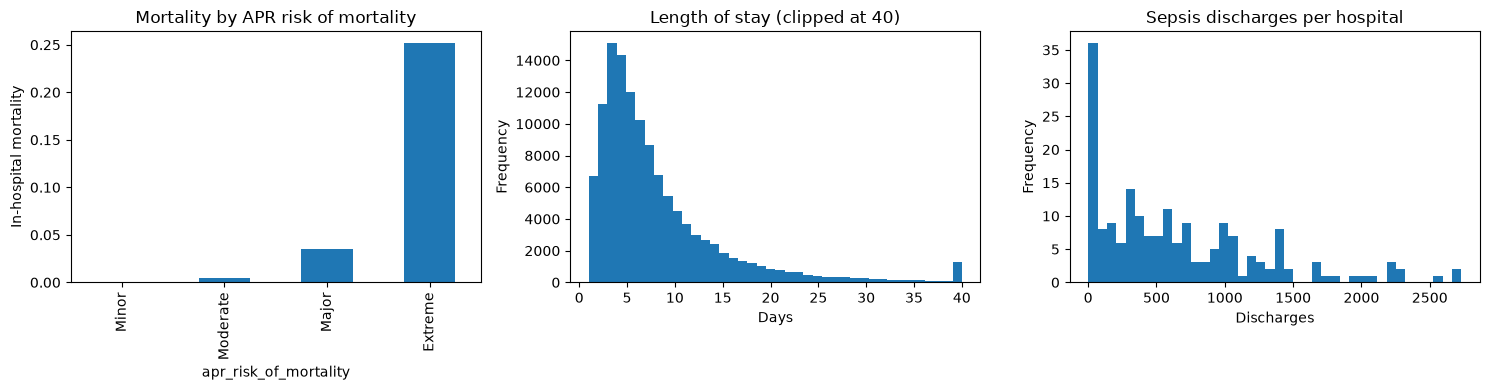

In [12]:
# Mortality by risk of mortality, length of stay, discharges per hospital
eda.plot_eda(df, FIGS / "eda.png")

# Mortality, cost and length of stay by severity of illness
display(eda.severity_table(df))

# Many hospitals are small, so their O/E will be noisy (handled by the funnel plot)
eda.hospital_sizes(df)

### 2f. Why not just compare raw death rates?
Hospitals see different patients. If a hospital's raw mortality mostly follows its share of very sick patients, ranking hospitals on raw rates measures case mix, not care. That's what risk adjustment fixes.

In [13]:
# Hospitals with 300+ cases (smaller ones have noisy rates), sorted by share of Extreme-risk patients
case_mix = eda.case_mix_table(df, min_n=300)
corr = case_mix["raw_mortality"].corr(case_mix["share_extreme"])
print(f"{len(case_mix)} hospitals with 300+ cases; "
      f"correlation of raw mortality with share Extreme = {corr:.2f}")

# Hospitals with the least and most severe patient mix
pd.concat([case_mix.head(3), case_mix.tail(3)]).round(3)

120 hospitals with 300+ cases; correlation of raw mortality with share Extreme = 0.53


,,n,raw_mortality,share_extreme
permanent_facility_id,facility_name,,,
000671,Geneva General Hospital,380,0.113,0.313
000628,UPSTATE University Hospital at Community General,753,0.046,0.317
000818,Saratoga Hospital,975,0.101,0.326
001165,Jacobi Medical Center,799,0.199,0.584
003975,New York-Presbyterian Hospital - Allen Hospital,720,0.171,0.644
001738,Richmond University Medical Center,493,0.239,0.649


### 2g. Is sepsis coded the same way everywhere?
Sepsis here is defined by billing codes. A hospital that codes sepsis liberally adds milder patients and looks better on raw mortality, with no change in care. An unusually high share of mild (severity 1-2) sepsis is a hint of that, not proof: some hospitals really do see milder sepsis.

In [14]:
# Share of each hospital's sepsis patients coded as mild, for hospitals with 100+ cases
mild = eda.mild_sepsis_share(df, min_n=100)
print(f"{len(mild)} hospitals; share mild ranges {mild.share_mild.min():.0%} to "
      f"{mild.share_mild.max():.0%}; correlation with raw mortality = "
      f"{mild.share_mild.corr(mild.raw_mortality):.2f}")

# Highest and lowest mild share
pd.concat([mild.head(3), mild.tail(3)]).round(3)

147 hospitals; share mild ranges 4% to 38%; correlation with raw mortality = -0.35


,,n,share_mild,raw_mortality
permanent_facility_id,facility_name,,,
001318,Wyckoff Heights Medical Center,728,0.376,0.102
000528,Nassau University Medical Center,650,0.375,0.155
000704,St Anthony Community Hospital,109,0.367,0.165
001463,NYU Langone Hospitals,2041,0.122,0.049
000885,Long Island Community Hospital at NYU Langone Health,1422,0.095,0.088
001453,Memorial Hospital for Cancer and Allied Diseases,1065,0.040,0.182


## 3. Risk models
Predict each patient's chance of dying in hospital at an average NY hospital, from patient factors only. The model is only a tool for expected deaths; nothing is predicted at admission. Code: `src/sparcs/models.py`.

**Feature rule:** a variable is allowed if the hospital's care can't change it (illness the patient arrived with), not because of when it's recorded.
- Out: hospital (shows up later as O/E), race (used for the fairness check), length of stay and cost (shaped by care).
- Severity of illness and risk of mortality (ROM) are coded at discharge and can absorb complications, so `admission_only` is kept as the other extreme.

Predictions are out-of-fold, split by hospital: each hospital is scored by a model that never saw its patients.

In [15]:
# Feature sets, one per sensitivity question (reasoning in models.FEATURE_SETS)
for name, cols in models.FEATURE_SETS.items():
    print(f"{name:16s} {cols}")

# Logistic regression on every feature set, LightGBM on the full set only
preds = models.fit_all(df)
y = df["died"].to_numpy()

# Discrimination (AUROC, AUPRC), accuracy of the probabilities (Brier), calibration
metrics = models.metrics_table(y, preds)
metrics.to_csv(RESULTS / "model_metrics.csv", index=False)
metrics

full             ['age_group', 'gender', 'type_of_admission', 'emergency_department_indicator', 'apr_severity_of_illness_code', 'apr_risk_of_mortality']
no_rom           ['age_group', 'gender', 'type_of_admission', 'emergency_department_indicator', 'apr_severity_of_illness_code']
full_plus_payer  ['age_group', 'gender', 'type_of_admission', 'emergency_department_indicator', 'apr_severity_of_illness_code', 'apr_risk_of_mortality', 'payment_typology_1']
full_plus_dx     ['age_group', 'gender', 'type_of_admission', 'emergency_department_indicator', 'apr_severity_of_illness_code', 'apr_risk_of_mortality', 'ccsr_diagnosis_description']
admission_only   ['age_group', 'gender', 'type_of_admission', 'emergency_department_indicator']


,model,auroc,auprc,brier,cal_intercept,cal_slope
0,lr_full,0.8081,0.2945,0.0937,-0.0020,0.9906
1,lr_no_rom,0.7839,0.2704,0.0962,-0.0018,0.9914
2,lr_full_plus_payer,0.8081,0.2949,0.0937,-0.0015,0.9880
3,lr_full_plus_dx,0.8084,0.2950,0.0937,-0.0016,0.9912
4,lr_admission_only,0.6021,0.1647,0.1073,-0.0017,0.9700
5,lgbm_full,0.8076,0.2921,0.0936,-0.0013,0.9709


### 3b. What drives risk? Odds ratios
Unpenalized logistic regression on the main feature set, with 95% CIs. Each odds ratio compares a group with its reference (e.g. ages 70+ vs 18 to 29). Severity and ROM are strongly related (Cramér's V 0.59), so they share credit: read them together, not one at a time.

In [16]:
odds = models.odds_ratios(df, models.FEATURE_SETS["full"])
print(f"rows dropped (categories under 50 patients): {odds.attrs['rows_dropped']}")
odds

rows dropped (categories under 50 patients): 3


odds_ratio   ci_low   ci_high  \
feature                        level                                          
age_group                      30 to 49           2.1293   1.6638    2.7250   
                               50 to 69           2.8980   2.2905    3.6665   
                               70 or Older        4.1778   3.3075    5.2771   
gender                         M                  0.9582   0.9235    0.9942   
type_of_admission              Elective           1.9096   1.5743    2.3164   
                               Not Available      0.4661   0.2144    1.0132   
                               Trauma             0.8546   0.5457    1.3381   
                               Urgent             1.1580   1.0307    1.3010   
emergency_department_indicator Y                  0.6018   0.5435    0.6662   
apr_severity_of_illness_code   2                  0.3245   0.1562    0.6740   
                               3                  0.6697   0.3221    1.3925   
                               4                  1.8693   0.8979    3.8916   
apr_risk_of_mortality          Extreme          228.4699  79.0505  660.3180   
                               Major             50.6673  17.5440  146.3277   
                               Moderate          13.5327   4.7074   38.9034   

                                              p_value  
feature                        level                   
age_group                      30 to 49        0.0000  
                               50 to 69        0.0000  
                               70 or Older     0.0000  
gender                         M               0.0233  
type_of_admission              Elective        0.0000  
                               Not Available   0.0540  
                               Trauma          0.4921  
                               Urgent          0.0135  
emergency_department_indicator Y               0.0000  
apr_severity_of_illness_code   2               0.0025  
                               3               0.2830  
                               4               0.0945  
apr_risk_of_mortality          Extreme         0.0000  
                               Major           0.0000  
                               Moderate        0.0000

## 4. Calibration
Do predicted risks match what actually happened? This matters more than AUROC here, because expected deaths are sums of predicted probabilities.

Two numbers summarize the plot:
- **Calibration intercept** ~0: predictions aren't too high or too low overall.
- **Calibration slope** ~1: predictions aren't too extreme (<1) or too timid (>1).

,cal_intercept,cal_slope
model,,
lr_full,-0.0020,0.9906
lr_no_rom,-0.0018,0.9914
lr_full_plus_payer,-0.0015,0.9880
lr_full_plus_dx,-0.0016,0.9912
lr_admission_only,-0.0017,0.9700
lgbm_full,-0.0013,0.9709


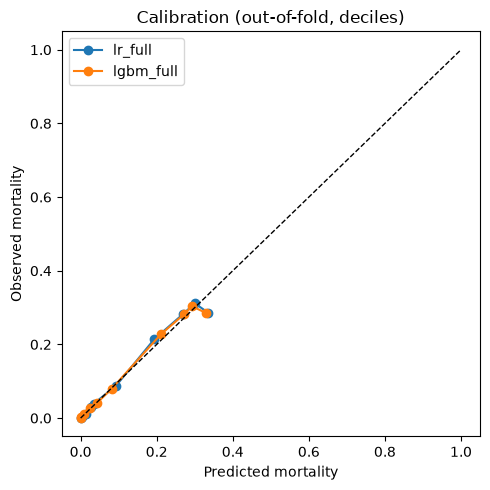

In [17]:
# Deciles of predicted risk: mean predicted vs observed mortality
models.plot_calibration(y, preds, FIGS / "calibration.png")
metrics.set_index("model")[["cal_intercept", "cal_slope"]]

## 5. Hospital observed vs expected (O/E) and funnel plot
- Observed (O) = actual deaths; expected (E) = sum of patients' predicted risks. O/E above 1 means more deaths than the patient mix explains.
- Each O/E gets an exact 95% CI.
- Small hospitals vary by chance, so flags use limits that widen as E shrinks:
  - **Poisson limits:** chance only.
  - **Adjusted limits:** chance plus the usual variation between hospitals (overdispersion; Spiegelhalter 2005). A hospital outside these stands out even from that normal spread.
- Many hospitals means some get flagged by chance alone; the 99.8% limit is the one that counts.
- Code: `src/sparcs/benchmark.py`.

phi = 4.95, tau2 = 0.0488, p = 4.3e-98
expected false flags: {'95%': 9.3, '99.8%': 0.4}


flag_adjusted,high (95%),high (99.8%),low (95%),low (99.8%),within,All
flag,,,,,,
high (95%),3,0,0,0,13,16
high (99.8%),10,6,0,0,12,28
low (95%),0,0,0,0,9,9
low (99.8%),0,0,9,1,10,20
within,0,0,0,0,113,113
All,13,6,9,1,157,186


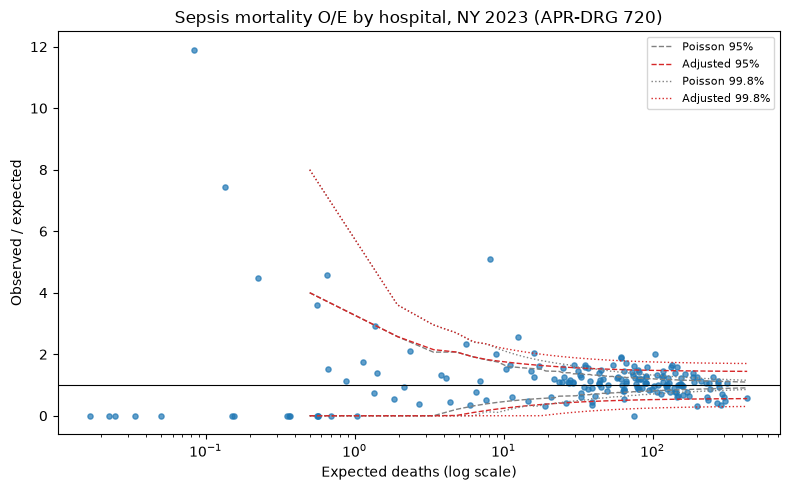

In [18]:
# O/E per hospital from the main model, with 95% CI and both flags
hosp = benchmark.hospital_oe(df, preds["lr_full"])
hosp.sort_values("oe", ascending=False).to_csv(RESULTS / "hospital_oe.csv", index=False)

# Do hospitals vary more than chance allows? phi well above 1 (tau2 > 0) says yes
od = hosp.attrs["overdispersion"]
print(f"phi = {od['phi']:.2f}, tau2 = {od['tau2']:.4f}, p = {od['p_value']:.1e}")

# Hospitals flagged by chance alone if none truly differed
print("expected false flags:",
      {k: round(v, 1) for k, v in benchmark.expected_false_flags(len(hosp)).items()})

benchmark.plot_funnel(hosp, FIGS / "funnel_plot.png",
                      f"Sepsis mortality O/E by hospital, NY 2023 (APR-DRG {APR_DRG})")

# Poisson flags (rows) vs overdispersion-adjusted flags (columns)
pd.crosstab(hosp["flag"], hosp["flag_adjusted"], margins=True)

In [19]:
# The strongest signals: outside the adjusted 99.8% limits
show = ["facility_name", "n", "observed", "expected", "oe", "oe_ci_low", "oe_ci_high", "flag"]
hosp[hosp["flag_adjusted"].str.contains("99.8")].sort_values("oe", ascending=False)[show].round(2)

,facility_name,n,observed,expected,oe,oe_ci_low,oe_ci_high,flag
132,Calvary Hospital Inc,45,41,8.05,5.09,3.65,6.91,high (99.8%)
9,"Brooks-TLC Hospital System, Inc.",169,32,12.55,2.55,1.74,3.60,high (99.8%)
120,St. Joseph's Medical Center,177,33,16.13,2.05,1.41,2.87,high (99.8%)
169,St Johns Episcopal Hospital So Shore,852,207,103.34,2.00,1.74,2.30,high (99.8%)
136,Brookdale Hospital Medical Center,431,117,61.05,1.92,1.59,2.30,high (99.8%)
137,Brooklyn Hospital Center - Downtown Campus,565,116,61.67,1.88,1.55,2.26,high (99.8%)
5,Our Lady of Lourdes Memorial Hospital,733,0,75.17,0.00,0.00,0.05,low (99.8%)


## 6. Sensitivity analyses
Do the hospital conclusions hold if we change the method?
- Drop APR risk of mortality (it can absorb complications that happened in hospital)
- Add payer
- Count hospice discharges as deaths

In [20]:
# Hospital O/E under each feature set
ranks = pd.DataFrame({name: benchmark.hospital_oe(df, preds[f"lr_{name}"]).set_index("permanent_facility_id")["oe"]
                      for name in models.FEATURE_SETS})

# Refit the main model on the hospice-as-death outcome and add its O/E
p_hosp = models.predict(df, "full", outcome="died_or_hospice")
hosp_hospice = benchmark.hospital_oe(df, p_hosp, "died_or_hospice").set_index("permanent_facility_id")
ranks["died_or_hospice"] = hosp_hospice["oe"]

# Spearman rank correlation: near 1 means hospitals keep roughly the same order
print(ranks.corr(method="spearman").round(3))

# Which hospitals change flag status when hospice counts as death?
flags = pd.DataFrame({"died": hosp.set_index("permanent_facility_id")["flag"],
                      "died_or_hospice": hosp_hospice["flag"]})
print(pd.crosstab(flags["died"], flags["died_or_hospice"]))

                  full  no_rom  full_plus_payer  full_plus_dx  admission_only  \
full             1.000   0.993            1.000         1.000           0.818   
no_rom           0.993   1.000            0.993         0.993           0.847   
full_plus_payer  1.000   0.993            1.000         1.000           0.818   
full_plus_dx     1.000   0.993            1.000         1.000           0.818   
admission_only   0.818   0.847            0.818         0.818           1.000   
died_or_hospice  0.894   0.887            0.893         0.893           0.734   

                 died_or_hospice  
full                       0.894  
no_rom                     0.887  
full_plus_payer            0.893  
full_plus_dx               0.893  
admission_only             0.734  
died_or_hospice            1.000  
died_or_hospice  high (95%)  high (99.8%)  low (95%)  low (99.8%)  within
died                                                                     
high (95%)                4            

## 7. Fairness check
Race is not a model input. Compare observed and expected mortality within each group: O/E near 1 means the model isn't systematically over- or under-predicting risk for that group.

In [21]:
# Mean observed vs mean predicted mortality by race, using the main model
fair = (df.assign(p=preds["lr_full"]).groupby("race")
          .agg(n=("died", "size"), observed=("died", "mean"), expected=("p", "mean")))
fair["oe"] = fair["observed"] / fair["expected"]
print(fair.round(3))

                            n  observed  expected     oe
race                                                    
Black/African American  17714     0.137     0.122  1.122
Multi-racial             1420     0.115     0.130  0.880
Other Race              28863     0.117     0.115  1.018
White                   73804     0.125     0.130  0.966
